# 04 — Multimodal Text & Image Fusion

Goal: Combine state-of-the-art text (TF-IDF + SVM, CamemBERT) and image models (ConvNeXt-Tiny) to maximise classification performance.

- **Image Model**: `ConvNeXt-Tiny` (Full Fine-Tuning + Smart Cropping from `notebooks/03_image_fineTuning/03_7_image_convnext_optimized.ipynb`), reaching **0.6998 Weighted F1** alone.
- **Text Models**: Calibrated `LinearSVC` (**0.8430 Weighted F1**) and fine-tuned `CamemBERT` (**0.8765 Weighted F1**).
- **Fusion Strategies**:
  1. **Soft Voting**: Probability average of the models. Equal weights on the three models, and weighted soft voting where the weights are chosen by cross-validation (SVM + image, CamemBERT + image, CamemBERT + SVM + image).
  2. **Stacking Classifier (Random Forest)**: Meta-classifier trained via 5-fold cross-validation on the combined 81-dimensional probability representations (27 classes × 3 models).


## 1. Text probabilities

We use the optimised text model from notebook 03_2 (all features, binary TF-IDF, LinearSVC with C = 1). A LinearSVC gives scores, not probabilities. Calibration learns on the training set (3-fold CV) how to turn these scores into probabilities.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import LinearSVC

# Resolve repository root directory
PROJECT_ROOT             = Path.cwd().resolve()
while PROJECT_ROOT.name in {"notebooks"}:
    PROJECT_ROOT         = PROJECT_ROOT.parent

from src.categories import CATEGORY_NAMES
from src.metrics import compute_per_class_metrics

DATA_PATH                = PROJECT_ROOT / "data" / "processed" / "text_train_processed.csv"
TEXT_PROBS_OUT           = PROJECT_ROOT / "data" / "processed" / "text_validation_probabilities.csv"
IMAGE_PREDS_PATH         = PROJECT_ROOT / "models" / "outputs" / "03_7_convnext_tiny_optimized_validation_predictions.csv"
CAMEMBERT_PROBS_PATH     = PROJECT_ROOT / "data" / "processed" / "camembert_validation_probabilities.csv"

RANDOM_STATE             = 42
CV_FOLDS                 = 5

data                     = pd.read_csv(DATA_PATH)
train                    = data[data["split"] == "train"]
validation               = data[data["split"] == "validation"]

vectorizer               = TfidfVectorizer(ngram_range=(1, 2), min_df=2, binary=True)
X_train                  = vectorizer.fit_transform(train["text_combined"])
X_validation             = vectorizer.transform(validation["text_combined"])

# Calibrated LinearSVC from notebook 03_2 (outputs well-calibrated class probabilities)
text_model               = CalibratedClassifierCV(LinearSVC(C=1, random_state=RANDOM_STATE), cv=3)
text_model.fit(X_train, train["prdtypecode"])
classes                  = text_model.classes_

text_probs               = pd.DataFrame(text_model.predict_proba(X_validation), columns=classes)
text_probs.insert(0, "row_id", validation["row_id"].to_numpy())
text_probs.to_csv(TEXT_PROBS_OUT, index=False)

print(f"Text probabilities saved: {text_probs.shape}")
print(f"Each row sums to 1      : {np.allclose(text_probs[classes].sum(axis=1), 1)}")


Text probabilities saved: (16984, 28)
Each row sums to 1      : True


## 2. Match text and image on the same products

In [2]:
# Best image model: ConvNeXt-Tiny (03_7_image_convnext_optimized)
image                    = pd.read_csv(IMAGE_PREDS_PATH)
image.columns            = [c.strip() for c in image.columns]
image_probs              = image[["row_id"] + [f"prob_{c}" for c in classes]]
image_probs.columns      = ["row_id"] + list(classes)

both                     = (
    validation[["row_id", "prdtypecode"]]
    .merge(text_probs,  on="row_id")
    .merge(image_probs, on="row_id", suffixes=("_text", "_image"))
)
y_true                   = both["prdtypecode"].to_numpy()
P_text                   = both[[f"{c}_text" for c in classes]].to_numpy()
P_image                  = both[[f"{c}_image" for c in classes]].to_numpy()

print(f"Products scored by both: {len(both):,}")


Products scored by both: 16,984


## 3. Combine the models

Text and image probabilities exist for the 16984 validation products, which none of the models were trained on. We score every method with 5-fold cross-validation on these products: the combiner learns on 4/5 of them and predicts the remaining 1/5. Every product is predicted by a combiner that never saw it.

Two ways to combine:
- Soft voting: average the probabilities of the models, then take the class with the highest average.
  - Equal weights: each of the three models counts 1/3. Nothing is chosen.
  - Weighted soft voting: each model gets its own weight (steps of 0.1, summing to 1). The weights are chosen on the 4/5 part only.
- Random Forest: a model that learns from the 81 probabilities (27 classes × 3 models) how to combine them.


Weighted soft voting (SVM + image) — weights chosen in each fold: [(0.6, 0.4), (0.6, 0.4), (0.6, 0.4), (0.6, 0.4), (0.6, 0.4)]
Weighted soft voting (CamemBERT + image) — weights chosen in each fold: [(0.5, 0.5), (0.5, 0.5), (0.5, 0.5), (0.5, 0.5), (0.5, 0.5)]
Weighted soft voting (CamemBERT + SVM + image) — weights chosen in each fold: [(0.4, 0.3, 0.3), (0.4, 0.3, 0.3), (0.3, 0.4, 0.3), (0.4, 0.3, 0.3), (0.4, 0.3, 0.3)]


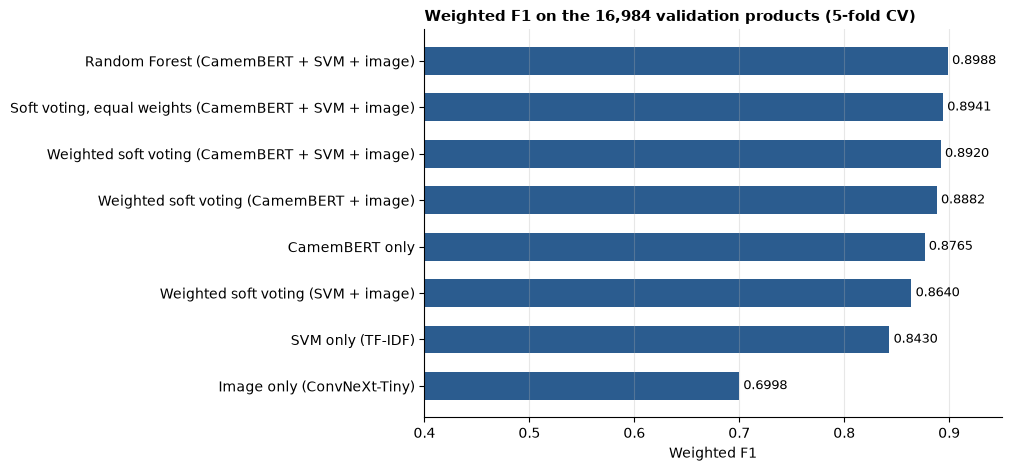

Model,Weighted F1,Macro F1,Errors
Random Forest (CamemBERT + SVM + image),0.8988,0.8856,1715
"Soft voting, equal weights (CamemBERT + SVM + image)",0.8941,0.8826,1776
Weighted soft voting (CamemBERT + SVM + image),0.8920,0.8797,1813
Weighted soft voting (CamemBERT + image),0.8882,0.8730,1875
CamemBERT only,0.8765,0.8594,2082
Weighted soft voting (SVM + image),0.8640,0.8548,2278
SVM only (TF-IDF),0.8430,0.8326,2656
Image only (ConvNeXt-Tiny),0.6998,0.6752,5043


In [3]:
camembert                = pd.read_csv(CAMEMBERT_PROBS_PATH)
P_camembert              = both[["row_id"]].merge(camembert, on="row_id")[[str(c) for c in classes]].to_numpy()

X_all                    = np.hstack([P_camembert, P_text, P_image])
folds                    = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
steps                    = np.round(np.arange(0, 1.01, 0.1), 1)
pairs                    = [(w, round(1 - w, 1)) for w in steps]
triples                  = [(a, b, round(1 - a - b, 1)) for a in steps for b in steps if a + b <= 1.001]

# Soft voting: the models to average and the weight combinations to try.
# Equal weights has a single option, so nothing is chosen for it.
soft_votes               = {
    "Soft voting, equal weights (CamemBERT + SVM + image)": ([P_camembert, P_text, P_image], [(1 / 3, 1 / 3, 1 / 3)]),
    "Weighted soft voting (SVM + image)"                  : ([P_text, P_image], pairs),
    "Weighted soft voting (CamemBERT + image)"            : ([P_camembert, P_image], pairs),
    "Weighted soft voting (CamemBERT + SVM + image)"      : ([P_camembert, P_text, P_image], triples),
}


def soft_vote(probs, weights, idx):
    return classes[sum(w * P[idx] for w, P in zip(weights, probs)).argmax(axis=1)]


predictions              = {
    "Image only (ConvNeXt-Tiny)"            : classes[P_image.argmax(axis=1)],
    "SVM only (TF-IDF)"                     : classes[P_text.argmax(axis=1)],
    "CamemBERT only"                         : classes[P_camembert.argmax(axis=1)],
    **{name: np.zeros_like(y_true) for name in soft_votes},
    "Random Forest (CamemBERT + SVM + image)": np.zeros_like(y_true),
}
chosen_weights           = {name: [] for name in soft_votes}

for train_idx, test_idx in folds.split(X_all, y_true):
    for name, (probs, grid) in soft_votes.items():
        fold_scores      = [f1_score(y_true[train_idx], soft_vote(probs, w, train_idx), average="weighted") for w in grid]
        best_w           = grid[int(np.argmax(fold_scores))]
        chosen_weights[name].append(tuple(round(float(w), 2) for w in best_w))
        predictions[name][test_idx] = soft_vote(probs, best_w, test_idx)

    forest               = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE)
    predictions["Random Forest (CamemBERT + SVM + image)"][test_idx] = forest.fit(X_all[train_idx], y_true[train_idx]).predict(X_all[test_idx])

for name, chosen in chosen_weights.items():
    if len(soft_votes[name][1]) > 1:
        print(f"{name} — weights chosen in each fold: {chosen}")
results                  = pd.DataFrame({
    "Model":       list(predictions),
    "Weighted F1": [f1_score(y_true, p, average="weighted") for p in predictions.values()],
    "Macro F1":    [f1_score(y_true, p, average="macro")    for p in predictions.values()],
    "Errors":      [int((p != y_true).sum()) for p in predictions.values()],
})
results.to_csv(PROJECT_ROOT / "models" / "outputs" / "04_fusion_results.csv", index=False)

fig, ax                  = plt.subplots(figsize=(10, 4.6), constrained_layout=True)
ordered                  = results.sort_values("Weighted F1")
bars                     = ax.barh(ordered["Model"], ordered["Weighted F1"], color="#2b5c8f", height=0.6)
ax.bar_label(bars, labels=[f"{v:.4f}" for v in ordered["Weighted F1"]], padding=3, fontsize=9)
ax.set_xlim(0.4, 0.95)
ax.set_title("Weighted F1 on the 16,984 validation products (5-fold CV)", loc="left", fontsize=11, fontweight="bold")
ax.set_xlabel("Weighted F1")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
plt.show()

display(results.sort_values("Weighted F1", ascending=False).style.hide(axis="index").format(precision=4, subset=["Weighted F1", "Macro F1"]))

### Analysis

- The best model is the Random Forest on CamemBERT, SVM and image: 0.8988 weighted F1 and 0.8856 macro F1.
- That is +2.2 points over CamemBERT alone (0.8765) and +5.6 points over the SVM alone (0.8430).
- Soft voting with equal weights on the three models reaches 0.8941. It already gives most of the gain.
- Weighted soft voting on the same three models reaches 0.8920 (weights 0.4 CamemBERT, 0.3 SVM, 0.3 image in 4 of 5 folds). Choosing the weights does not help: equal weights are 0.2 points better.
  - The reason is the grid: weights move in steps of 0.1, so 1/3 cannot be chosen. The closest options are 0.4/0.3/0.3 and 0.3/0.4/0.3.
  - Equal weights also score best on the 4/5 part of every fold, so the search would pick them if 1/3 were in the grid. The 0.2-point gap is within noise.
- Weighted soft voting with CamemBERT and image (0.5 each) reaches 0.8882. With SVM and image (0.6 SVM, 0.4 image) it reaches 0.8640.
- The weights are almost the same in every fold, so the choice is stable.
- We also tried Gradient Boosting instead of Random Forest (appendix notebook). It scored slightly lower and was much slower, so we kept the Random Forest.


## 4. Per category: best fusion vs CamemBERT

In [4]:
best                     = "Random Forest (CamemBERT + SVM + image)"
camembert_scores         = compute_per_class_metrics(y_true, predictions["CamemBERT only"], classes)
best_scores              = compute_per_class_metrics(y_true, predictions[best], classes)

per_class                = pd.DataFrame({
    "Code":           classes,
    "Category":       [CATEGORY_NAMES[c] for c in classes],
    "CamemBERT F1":   camembert_scores["f1"],
    "Best fusion F1": best_scores["f1"],
})
per_class["Gain"]        = per_class["Best fusion F1"] - per_class["CamemBERT F1"]
per_class.to_csv(PROJECT_ROOT / "models" / "outputs" / "04_fusion_per_class.csv", index=False)
display(per_class.sort_values("Gain", ascending=False).style.hide(axis="index").format(precision=3))


Code,Category,CamemBERT F1,Best fusion F1,Gain
2705,New Books,0.818,0.926,0.108
10,Used Books,0.689,0.788,0.099
1180,Wargames,0.614,0.706,0.093
40,Games,0.795,0.855,0.059
1302,Outdoor Toys,0.810,0.853,0.043
1140,Figurines,0.834,0.862,0.028
60,Consoles,0.876,0.903,0.027
1940,Food,0.946,0.969,0.023
1160,Cards,0.955,0.978,0.023
1320,Baby,0.856,0.877,0.021


### Analysis

- The best fusion is better than CamemBERT on 26 of the 27 categories. Only Baby Socks drops slightly (-0.3 points).
- The largest gains are on New Books (+10.8 points), Used Books (+9.9) and Wargames (+9.3).
- Books gain the most from the image: the cover shows if a book is new, used, or a lot of several books.
- Wargames was CamemBERT's weakest category. The SVM catches its rare exact words (*warhammer*, *heroclix*), so combining both fixes it.


## 5. Best fusion vs weighted soft voting

The Random Forest against the best weighted soft voting (CamemBERT + SVM + image), per category, on the same 5-fold predictions.

In [5]:
soft_best                = "Weighted soft voting (CamemBERT + SVM + image)"
soft_scores              = compute_per_class_metrics(y_true, predictions[soft_best], classes)

versus                   = pd.DataFrame({
    "Code":                 classes,
    "Category":             [CATEGORY_NAMES[c] for c in classes],
    "Weighted soft voting": soft_scores["f1"],
    "Random Forest":        best_scores["f1"],
})
versus["Gain"]           = versus["Random Forest"] - versus["Weighted soft voting"]

soft_errors              = int((predictions[soft_best] != y_true).sum())
forest_errors            = int((predictions[best] != y_true).sum())
print(f"Errors: weighted soft voting {soft_errors}, Random Forest {forest_errors} ({soft_errors - forest_errors} fewer)")
print(f"Categories where the Random Forest is better: {(versus['Gain'] > 0).sum()} of {len(versus)}")
display(versus.sort_values("Gain", ascending=False).style.hide(axis="index").format(precision=3))

Errors: weighted soft voting 1813, Random Forest 1715 (98 fewer)
Categories where the Random Forest is better: 18 of 27


Code,Category,Weighted soft voting,Random Forest,Gain
2705,New Books,0.884,0.926,0.042
10,Used Books,0.757,0.788,0.031
60,Consoles,0.885,0.903,0.019
1281,Board Games,0.684,0.700,0.016
1300,RC Models,0.973,0.987,0.014
1280,Toys,0.789,0.803,0.014
40,Games,0.841,0.855,0.014
1920,Textiles,0.925,0.938,0.013
1940,Food,0.957,0.969,0.012
50,Game Accessories,0.886,0.896,0.010


### Analysis

- The Random Forest makes 1715 errors against 1813 for weighted soft voting (98 fewer). Weighted F1: 0.8988 against 0.8920.
- It is better on 18 of the 27 categories. The largest gains are on New Books (+4.2 points), Used Books (+3.1) and Consoles (+1.9).
- These are the categories where one model should be trusted more than the others. For books, the image tells new from used. Soft voting uses the same weights for every category, so it cannot do this.
- On 9 categories, weighted soft voting is slightly better, by at most 1.2 points (Garden Furniture). Wargames, Used Games and Baby lose about 1 point.
- So the Random Forest gains most of its lead on a few categories, mainly books.

## Conclusion

- Combining models helps. Soft voting on the three models already reaches 0.8941 with equal weights. Choosing the weights does not improve it.
- A learned combination (Random Forest) adds 0.5 points more, mainly on the book categories.
- Best model: Random Forest on the CamemBERT, SVM and ConvNeXt probabilities, with 0.8988 weighted F1 on the validation products (5-fold CV).
- Each part adds something: CamemBERT reads context, the SVM catches rare specific words, and the image helps on books.